* https://www.cancer.gov/about-cancer/treatment/drugs/breast

In [16]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns
import matplotlib.colors as mcolors

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"
mpl.rcParams["mathtext.default"] = "regular"

# molecular cause connectivity

### encode molecules

In [1]:
import sys
sys.path.append('../UniPert')
from unipert import UniPert

unipert = UniPert(data_dir='../UniPert/data')

💡 Model have already trained at /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/current_model. 
💡 UniPert model hyperparameters settings:
Loading model from /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/current_model...
💡 Constructing UniPert model...
✅ ESM2 model loaded.
✅ Reference ESM2 embedding file loaded.
✅ ESM2 embedder created.
✅ ECFP4 embedder loaded.
✅ UniPert model constructed.
✅ Pretrained model file loaded.
💡 Building a weighted_directed graph...
✅ Reference target graph prepared.


In [2]:
ER_drug_emb = unipert.encode_chemical_perturbagens_from_cp_sms_csv(
    custom_cp_sms_csv='/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/data/ESR1_drugs.csv',
    cp_col_name='compound_name',
    sms_col_name='canonical_smiles',
    )

✅ Referece representations loaded.


100%|██████████| 5/5 [00:00<00:00, 68.49it/s]


In [3]:
ER_drugs = list(ER_drug_emb.keys())
ER_drugs

['Estradiol', 'Tamoxifen', 'Raloxifene', 'Fulvestrant', 'Elacestrant']

In [4]:
ER_var_emb = unipert.encode_genetic_perturbagens_from_fasta(
    custom_seq_fasta='/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/data/ESR1_mutant_domain_seq.fasta'
)

✅ Referece representations loaded.
💡 Constructing reference-custom target graph from /data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/data/ESR1_mutant_domain_seq.fasta...
💡 Preparing MMseqs and creating reference database in /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/mmseqs_storage...
createdb ../UniPert/data/ref_target_seq.fasta /data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/mmseqs_storage/ref 

MMseqs Version:                    	bd01c2229f027d8d8e61947f44d11ef1a7669212
Database type                      	0
Shuffle input database             	true
Createdb mode                      	0
Write lookup file                  	1
Offset of numeric ids              	0
Threads                            	192
Compressed                         	0
Mask residues                      	0
Mask residues probability          	0.9
Mask lower case residues           	0
Mask lower letter repeating N times	0
Use GPU                            	0
Verbosity                          	3

C

100%|██████████| 8/8 [00:00<00:00, 33.18it/s]

✅ ESM2 embeddings with 8 querys generated.


✅ Reference-custom target graph created with 19194 nodes and 791608 edges.


In [5]:
ESR1s = unipert.custom_target
ESR1s

['P03372_AF1',
 'P03372_Y537S_D538G',
 'P03372',
 'P03372_Y537S',
 'P03372_DBD',
 'P03372_AF2',
 'P03372_Hinge',
 'P03372_D538G']

In [6]:
import pickle
save_dir = f'/data/liyiming/Project/UniPert-G2CP_reproduce/UniPert/current_model/unipert_reps.pkl'
with open(save_dir, 'rb') as f:
    unipert_reps = pickle.load(f)

unipert_reps.update(ER_drug_emb)
unipert_reps.update(ER_var_emb)

In [7]:
ER_agonist = '17-beta-estradiol|coumestrol|daidzein|diarylpropionitrile|dienestrol|diethylstilbestrol|equilin|estradiol|estradiol-benzoate|estradiol-cypionate|estradiol-valerate|estriol|estrone|estropipate|ethinyl-estradiol|mestranol|PPT'.split('|')
ER_agonist_brd = 'BRD-K66766661|BRD-K97509413|BRD-K42095107|BRD-A27143604|BRD-K95309561|BRD-K45330754|BRD-K04046242|BRD-A18917088|BRD-A36066264|BRD-A91452556|BRD-A39747742|BRD-A18620900|BRD-K81839095|BRD-A22143024|BRD-A02367930|BRD-A14798026|BRD-K00312224'.split('|')
brd2cp = dict(zip(ER_agonist_brd, ER_agonist))
cp2brd = dict(zip(ER_agonist, ER_agonist_brd))

ranked_ER_agonist = [
'diarylpropionitrile',
'coumestrol',
'estropipate',
'ethinyl-estradiol',
'mestranol',
'estriol',
'estrone',
'estradiol',
'estradiol-benzoate',
'estradiol-cypionate',
'estradiol-valerate',
'17-beta-estradiol',
'PPT',
'equilin',
'diethylstilbestrol',
'daidzein',
'dienestrol']

ranked_ER_agonist_brd = [cp2brd[cp] for cp in ranked_ER_agonist]

In [ ]:
ER_case_reps = {}
for i in ER_drugs + ESR1s:
    ER_case_reps[i] = unipert_reps[i]
for i in ER_agonist_brd:
    ER_case_reps[i] = unipert_reps[i]
    ER_case_reps[brd2cp[i]] = unipert_reps[i]

In [9]:
ER_case_reps.keys()

dict_keys(['Estradiol', 'Tamoxifen', 'Raloxifene', 'Elacestrant', 'Fulvestrant', 'P03372_AF1', 'P03372_Y537S_D538G', 'P03372', 'P03372_Y537S', 'P03372_DBD', 'P03372_AF2', 'P03372_Hinge', 'P03372_D538G', 'BRD-K66766661', '17-beta-estradiol', 'BRD-K97509413', 'coumestrol', 'BRD-K42095107', 'daidzein', 'BRD-A27143604', 'diarylpropionitrile', 'BRD-K95309561', 'dienestrol', 'BRD-K45330754', 'diethylstilbestrol', 'BRD-K04046242', 'equilin', 'BRD-A18917088', 'estradiol', 'BRD-A36066264', 'estradiol-benzoate', 'BRD-A91452556', 'estradiol-cypionate', 'BRD-A39747742', 'estradiol-valerate', 'BRD-A18620900', 'estriol', 'BRD-K81839095', 'estrone', 'BRD-A22143024', 'estropipate', 'BRD-A02367930', 'ethinyl-estradiol', 'BRD-A14798026', 'mestranol', 'BRD-K00312224', 'PPT'])

In [ ]:
# with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_unipert_reps.pkl', 'wb') as f:
#     pickle.dump(ER_case_reps, f)

## cal unipert similarity

In [12]:
import pickle

with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_unipert_reps.pkl', 'rb') as f:
    ER_case_reps = pickle.load(f)


In [14]:
ESR1s = [
    'P03372_AF2',
    'P03372_DBD',
    'P03372_Y537S',
    'P03372_Hinge',
    'P03372',
    'P03372_AF1',
    'P03372_Y537S_D538G',
    'P03372_D538G']

ER_drugs = ['Estradiol', 'Tamoxifen', 'Raloxifene', 'Elacestrant', 'Fulvestrant']

In [17]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

targets = ESR1s
compound_names = ranked_ER_agonist_brd + ER_drugs

unipert_sims = {}
for brd in compound_names:
    for target in targets:
        cos_sim = cosine_similarity(ER_case_reps[brd].reshape(1, -1), ER_case_reps[target].reshape(1, -1))[0][0]
        # print(cos_sim, '\t', brd, '\t', target , '\t', brd2cp[brd])
        unipert_sims[(target, brd)] = cos_sim

similarity_matrix = []
for target in targets:
    row = []
    for brd in compound_names:
        sim = unipert_sims.get((target, brd), np.nan)
        row.append(sim)
    similarity_matrix.append(row)

sim_df = pd.DataFrame(similarity_matrix, 
                      index=targets, 
                      columns=ranked_ER_agonist+ ER_drugs)


In [18]:
sim_df.T.sort_values(by='P03372', ascending=False)

,P03372_AF2,P03372_DBD,P03372_Y537S,P03372_Hinge,P03372,P03372_AF1,P03372_Y537S_D538G,P03372_D538G
estriol,0.315244,0.314630,0.314893,0.007513,0.314676,0.016314,0.314893,0.314892
diarylpropionitrile,0.302278,0.304180,0.303524,-0.101730,0.304533,0.002249,0.303523,0.303522
Elacestrant,0.301231,0.298376,0.299432,0.073215,0.297893,-0.016028,0.299433,0.299433
equilin,0.285673,0.286751,0.286383,-0.059520,0.286861,-0.006058,0.286382,0.286383
Fulvestrant,0.256909,0.257095,0.257047,-0.067759,0.257122,0.008713,0.257047,0.257047
mestranol,0.252010,0.252658,0.252452,-0.041167,0.252955,0.024440,0.252450,0.252449
PPT,0.248529,0.247637,0.247991,-0.028506,0.247543,-0.006662,0.247992,0.247991
ethinyl-estradiol,0.243672,0.244281,0.244089,-0.024576,0.244541,0.049980,0.244088,0.244087
estradiol-cypionate,0.231405,0.232275,0.231969,-0.031624,0.232438,0.020601,0.231967,0.231967
estradiol-valerate,0.223467,0.224117,0.223896,0.006924,0.224370,0.014168,0.223894,0.223893


## plot

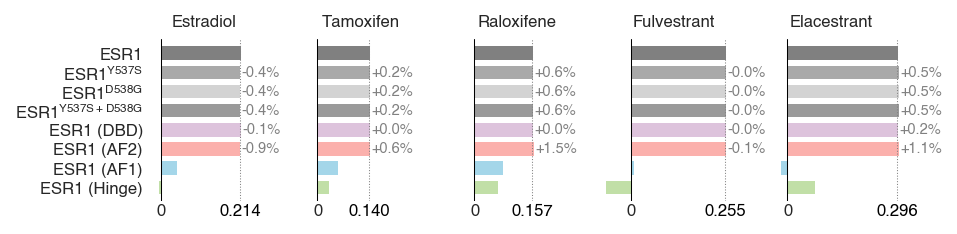

In [20]:
cols = ["Estradiol", "Tamoxifen", "Raloxifene", "Fulvestrant", "Elacestrant"]
rows = ["P03372","P03372_Y537S", "P03372_D538G", "P03372_Y537S_D538G", "P03372_DBD", "P03372_AF2", "P03372_AF1", "P03372_Hinge"][::-1]
domain_map = {"DBD": "DBD", "AF1": "AF1", "AF2": "AF2", "HINGE": "Hinge"}

def format_row_label(r: str) -> str:
    if r == "P03372":
        return "ESR1"
    if r.startswith("P03372_"):
        suffix = r.split("P03372_", 1)[1]
        key = suffix.upper()
        if key in domain_map:
            return f"ESR1 ({domain_map[key]})"
        if key == "Y537S_D538G":
            return rf"ESR1$^{{Y537S+D538G}}$"
        return rf"ESR1$^{{{suffix}}}$" 
    return r
row_labels = [format_row_label(r) for r in rows]

plot_df = sim_df.loc[rows, cols].copy()
plot_df.index = [format_row_label(r) for r in rows]

base = plot_df.loc["ESR1"]  # Series, index=cols
pct_df = (plot_df.sub(base, axis=1)
                 .div(base.replace(0, np.nan), axis=1)
                 .mul(100))
pct_df.loc["ESR1"] = 0

annot_rows = ["ESR1 (DBD)", "ESR1 (AF2)", r"ESR1$^{Y537S}$", r"ESR1$^{D538G}$", r"ESR1$^{Y537S+D538G}$"]
row_to_y = {lab: i for i, lab in enumerate(plot_df.index)}

label_color = {
    "ESR1": "gray",         

    "ESR1 (AF1)": "#A4D6E9",   
    "ESR1 (DBD)": "#DDC3DC", 
    "ESR1 (Hinge)": "#C1DFA7",  
    "ESR1 (AF2)": "#FBB0AC",   
    r"ESR1$^{Y537S}$": "darkgray",
    r"ESR1$^{D538G}$": "lightgray",
}
bar_colors = [label_color.get(lbl, "#9A9A9A") for lbl in row_labels]


xmin = float(plot_df.min().min())
xmax = float(plot_df.max().max())
pad = 0.02 * (xmax - xmin) if xmax > xmin else 0.1
xmin, xmax = xmin - pad, xmax + pad

bar_height = 0.7 
fig, axes = plt.subplots(1, len(cols), figsize=(6.5, 1.7), sharey=True)

y = np.arange(len(plot_df.index))

for ax, col in zip(axes, cols):
    x_range = (xmax - xmin) if xmax > xmin else 1.0
    pad_x = 0.01 * x_range  

    for lab in annot_rows:
        if lab not in row_to_y:
            continue
        yi = row_to_y[lab]
        val = float(plot_df.loc[lab, col])
        pct = float(pct_df.loc[lab, col])

        txt = f"{pct:+.1f}%"  
        if val >= 0:
            x_text = val + pad_x
            ha = "left"
        else:
            x_text = val - pad_x
            ha = "right"

        ax.text(x_text, yi, txt, ha=ha, va="center", fontsize=7, color="gray")

    ax.barh(y, plot_df[col].values, height=bar_height,
            color=bar_colors, edgecolor="none", linewidth=0)

    ax.set_title(col, fontsize=8)
    ax.set_xlim(xmin, xmax)
    ax.set_xticks([])

    ax.set_yticks(y)
    ax.set_yticklabels(plot_df.index)
    for t in ax.get_yticklabels():
        t.set_ha("right") 
    ax.tick_params(axis="y", pad=-5)

    ax.axvline(0.0, linestyle="-", linewidth=0.5, color="black")
    ax.text(-0.01, -1.5, f"0",fontsize=8)

    if "ESR1" in plot_df.index:
        esr1_val = float(plot_df.loc["ESR1", col])-0.002
        ax.axvline(esr1_val, linestyle=":", linewidth=0.5, color="gray")
        x_offset = 0.01 * (xmax - xmin) if xmax > xmin else 0.02
        ax.text(esr1_val, -1.5, f"{esr1_val:.3f}", ha="center", fontsize=8, color="black")


    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", length=0)

plt.tight_layout()
fig.subplots_adjust(wspace=0.1)
plt.show()

# phenotypic effect connectivity

### inference and load cell line-specific genetic & chemical perturbation effect

In [ ]:
# !nohup python inference_cell_line_genetic_perturb_effect.py > inference_ESR1.log 2>&1 &
# !nohup python inference_cell_line_chemical_perturb_effect.py > inference_ESR1_drugs.log 2>&1 &

In [ ]:
import scanpy as sc
import os

datasets = ['LINCS-A549', 'LINCS-A375', 'LINCS-MCF7', 'LINCS-PC3', 'LINCS-HT29']

folder1 = '/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/data/LINCS/'
folder2 = '/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/in_silico_genetic_perturb_effect/'
folder3 = '/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/in_silico_chemical_perturb_effect/'

real_effect_dict = {}
simu_gene_effect_dict = {}
simu_chem_effect_dict = {}
for dataset in datasets:
    cell_line = dataset.split('-')[1]
    print(cell_line)

    adata1 = sc.read(os.path.join(folder1, f'{cell_line}/{cell_line}_gene_chem_ctrl_adata.h5ad'))
    adata2 = sc.read(os.path.join(folder2, f'{dataset}_in_silico_effect_adata.h5ad'))
    adata3 = sc.read(os.path.join(folder3, f'{dataset}_in_silico_effect_adata.h5ad'))
    adata2.var = adata1.var
    landmarks = adata1.var_names

    real_effect_dict[cell_line] = adata1
    simu_gene_effect_dict[cell_line] = adata2
    simu_chem_effect_dict[cell_line] = adata3

A549
A375
MCF7
PC3
HT29


## cal effect connectivity

In [8]:
ESR1s = ['P03372_AF1',
 'P03372_Y537S_D538G',
 'P03372',
 'P03372_Y537S',
 'P03372_DBD',
 'P03372_AF2',
 'P03372_Hinge',
 'P03372_D538G']

In [10]:
ER_agonist = '17-beta-estradiol|coumestrol|daidzein|diarylpropionitrile|dienestrol|diethylstilbestrol|equilin|estradiol|estradiol-benzoate|estradiol-cypionate|estradiol-valerate|estriol|estrone|estropipate|ethinyl-estradiol|mestranol|PPT'.split('|')
ER_agonist_brd = 'BRD-K66766661|BRD-K97509413|BRD-K42095107|BRD-A27143604|BRD-K95309561|BRD-K45330754|BRD-K04046242|BRD-A18917088|BRD-A36066264|BRD-A91452556|BRD-A39747742|BRD-A18620900|BRD-K81839095|BRD-A22143024|BRD-A02367930|BRD-A14798026|BRD-K00312224'.split('|')
brd2cp = dict(zip(ER_agonist_brd, ER_agonist))
cp2brd = dict(zip(ER_agonist, ER_agonist_brd))

ranked_ER_agonist = [
'diarylpropionitrile',
'coumestrol',
'estropipate',
'ethinyl-estradiol',
'mestranol',
'estriol',
'estrone',
'estradiol',
'estradiol-benzoate',
'estradiol-cypionate',
'estradiol-valerate',
'17-beta-estradiol',
'PPT',
'equilin',
'diethylstilbestrol',
'daidzein',
'dienestrol']

ranked_ER_agonist_brd = [cp2brd[cp] for cp in ranked_ER_agonist]

In [ ]:
import pickle

with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_unipert_reps.pkl', 'rb') as f:
    ER_case_reps = pickle.load(f)


In [13]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
sys.path.insert(0,"/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/run_scripts")
from cmap_utils import *

simu_connects = {}
res = []

for target in ESR1s:
    print(target)
    for dataset in datasets:
        cell_line = dataset.split('-')[1]
        simu_chem_adata = simu_chem_effect_dict[cell_line]
        simu_gene_adata = simu_gene_effect_dict[cell_line]
        simu_gene_tgt_effect = simu_gene_adata[simu_gene_adata.obs['condition'] == target].X.mean(axis=0)
        
        for brd in ranked_ER_agonist_brd:
            ### cause connectivity
            brd_tgt_cause = cosine_similarity(ER_case_reps[brd].reshape(1, -1), ER_case_reps[target].reshape(1, -1))[0][0]

            ### effect connectivity
            tgt_simu_gene_effect = simu_gene_adata[simu_gene_adata.obs['condition'] == target].X.mean(axis=0)
            brd_simu_effect = simu_chem_adata[simu_chem_adata.obs['condition'] == brd].X.mean(axis=0)
            simu_gene_wtcs, _, _ = calculate_wtcs(brd_simu_effect, tgt_simu_gene_effect, list(landmarks), n_genes=100)

            # res.append([cell_line, target, brd if brd in brd2cp else brd, brd_tgt_cause, simu_gene_wtcs])
            simu_connects[(cell_line, target, brd2cp[brd])] = simu_gene_wtcs

        for brd in ER_drugs:
            ### cause connectivity
            brd_tgt_cause = cosine_similarity(ER_case_reps[brd].reshape(1, -1), ER_case_reps[target].reshape(1, -1))[0][0]

            ### effect connectivity
            tgt_simu_gene_effect = simu_gene_adata[simu_gene_adata.obs['condition'] == target].X.mean(axis=0)
            brd_simu_effect = simu_chem_adata[simu_chem_adata.obs['condition'] == brd].X.mean(axis=0)
            simu_gene_wtcs, _, _ = calculate_wtcs(brd_simu_effect, tgt_simu_gene_effect, list(landmarks), n_genes=100)

            simu_connects[(cell_line, target, brd)] = simu_gene_wtcs


P03372_AF1
P03372_Y537S_D538G
P03372
P03372_Y537S
P03372_DBD
P03372_AF2
P03372_Hinge
P03372_D538G


## plot cell line ✖️ ER_agonist connectivity in cause-effect spaces

(5, 17) 0.6766017011587371 0.9161878862601036


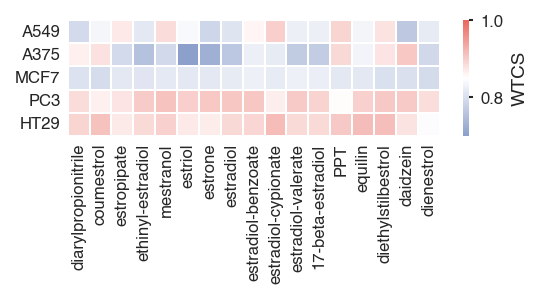

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

target = 'P03372'
compounds = ranked_ER_agonist
cell_lines = [dataset.split('-')[1] for dataset in datasets]

# Finetuned-simulated-compound vs Pretrained-simulated-target effect Connectivity 
simu_data = []
for cell_line in cell_lines:
    row = [simu_connects[(cell_line, target, cp)] for cp in compounds]
    simu_data.append(row)

simu_df = pd.DataFrame(simu_data, index=cell_lines, columns=ranked_ER_agonist)

custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#8CA0CB", "w", "#E9685E"])
A = simu_df.values.astype(float)
vmin, vmax = np.nanmin(A), np.nanmax(A)
print(A.shape,vmin, vmax)

plt.figure(figsize=(4, 1))
sns.heatmap(simu_df, 
            fmt='.3f', 
            cmap=custom_cmap,
            vmin=0.7, vmax=1, 
            cbar_kws={'label': 'WTCS'},
            linewidths=0.01,
            linecolor='white',
            xticklabels=True,
            yticklabels=True
            )
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tick_params(length=0)
plt.tight_layout()
plt.show()

(1, 17) 0.16684237122535706 0.3146761655807495


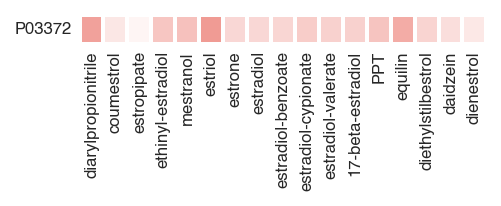

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

s = sim_df.loc[target, ranked_ER_agonist]
one_row_df = pd.DataFrame([s.values], index=[target], columns=ranked_ER_agonist)

A = one_row_df.values.astype(float)
vmin, vmax = np.nanmin(A), np.nanmax(A)
print(A.shape,vmin, vmax)

plt.figure(figsize=(3.5, 0.25))
sns.heatmap(
    one_row_df,
    fmt=".3f",
    cmap=custom_cmap,
    vmin=-0.1, vmax=0.4,
    linewidths=1,
    linecolor="white",
    xticklabels=ranked_ER_agonist,
    yticklabels=True,
    cbar=False
)

plt.yticks(rotation=0)
plt.tick_params(length=0)
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

def _to_dense_1d(x):
    if sp.issparse(x):
        x = x.A
    x = np.asarray(x)
    if x.ndim == 2:
        x = x.squeeze()
    return x

def mean_effect_by_obs_value(adata, obs_key, obs_values, genes=None):
    if obs_key not in adata.obs.columns:
        raise KeyError(f"[mean_effect_by_obs_value] obs_key='{obs_key}' not in adata.obs.columns: {list(adata.obs.columns)}")

    m = adata.obs[obs_key].isin(obs_values).values
    if m.sum() == 0:
        raise ValueError(f"No cells matched {obs_key} in {obs_values}")

    ad = adata[m].copy()
    ad.var_names = ad.var_names.astype(str)

    if genes is not None:
        genes = [g for g in genes if g in ad.var_names]
        if len(genes) == 0:
            raise ValueError("None of the requested genes exist in adata.var_names")
        ad = ad[:, genes].copy()

    x_mean = ad.X.mean(axis=0)
    return _to_dense_1d(x_mean)

def mean_effect_by_single_value(adata, obs_key, obs_value, genes=None):
    return mean_effect_by_obs_value(adata, obs_key, [obs_value], genes=genes)



def build_effect_matrix_for_cellline(
    cell_line,
    real_effect_dict,
    simu_chem_effect_dict,
    simu_gene_effect_dict,
    obs_key_control, control_values,
    obs_key_compound, compounds,
    obs_key_target, targets,
    genes_to_plot=None
):
    ad_real = real_effect_dict[cell_line]
    ad_fin  = simu_chem_effect_dict[cell_line]
    ad_pre  = simu_gene_effect_dict[cell_line]

    ad_fin.var_names = ad_real.var_names.astype(str)
    ad_pre.var_names = ad_real.var_names.astype(str)

    if genes_to_plot is None:
        genes = list(ad_real.var_names)
    else:
        genes = [g for g in genes_to_plot if g in ad_real.var_names]
        if len(genes) == 0:
            raise ValueError(f"[{cell_line}] None of genes_to_plot found in adata.var_names")

    row_labels = []
    rows = []

    ctrl_vec = mean_effect_by_obs_value(ad_real, obs_key_control, control_values, genes=genes)
    row_labels.append(f"{cell_line}:CONTROL")
    rows.append(ctrl_vec)

    for t in targets:
        v = mean_effect_by_single_value(ad_pre, obs_key_target, t, genes=genes)
        row_labels.append(f"{cell_line}:TGT:{t}")
        rows.append(v)

    for c in compounds:
        v = mean_effect_by_single_value(ad_fin, obs_key_compound, c, genes=genes)
        row_labels.append(f"{cell_line}:CMPD:{c}")
        rows.append(v)

    mat = np.vstack(rows)  # shape: (n_rows, n_genes)

    df = pd.DataFrame(mat, index=row_labels, columns=genes)
    return df

In [30]:
inferenced_effect_dict = {}
cell_lines = ['MCF7','A549','PC3','A375','HT29']
targets = ['P03372', 'P03372_Y537S', 'P03372_D538G', 'P03372_Y537S_D538G']
compounds = ['Estradiol', 'Tamoxifen','Raloxifene','Fulvestrant','Elacestrant']
domains = ['P03372_Hinge', 'P03372_AF1', 'P03372_AF2', 'P03372_DBD'] 
obs_key_control = "condition" 
control_values = ["ctrl"]
obs_key_compound = "condition"
obs_key_target = "condition"

for cell_line in cell_lines:
    print(cell_line)

    df = build_effect_matrix_for_cellline(
        cell_line=cell_line,
        real_effect_dict=real_effect_dict,
        simu_chem_effect_dict=simu_chem_effect_dict,
        simu_gene_effect_dict=simu_gene_effect_dict,
        obs_key_control=obs_key_control, 
        control_values=control_values,
        obs_key_compound=obs_key_compound, 
        compounds=compounds,
        obs_key_target=obs_key_target, 
        targets=targets+domains,
        genes_to_plot=None
    )
    inferenced_effect_dict[cell_line] = df

MCF7
A549
PC3
A375
HT29


In [ ]:
# import pickle

# with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_inferenced_effect.pkl', 'wb') as f:
#     pickle.dump(inferenced_effect_dict, f)

# with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_inferenced_effect.pkl', 'rb') as f:
#     inferenced_effect_dict = pickle.load(f)


## in silico perturbation effect distribution in MCF7

In [31]:
import pickle

with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_inferenced_effect.pkl', 'rb') as f:
    inferenced_effect_dict = pickle.load(f)


In [33]:
import numpy as np
import pandas as pd

merged_df = pd.concat([df for df in inferenced_effect_dict.values()], axis=0, join="outer")
mcf7_df = inferenced_effect_dict['MCF7']
mcf7_df.index = mcf7_df.index.str.split(':').str[-1]
mcf7_df


,GNPDA1,CDH3,HDAC6,PARP2,MAMLD1,DNAJB6,SMC4,ABCC5,ABCB6,DNM1L,...,NCAPD2,PAN2,LPGAT1,KIF14,CDC25A,CDC25B,OXSR1,MVP,CDC42,DMTF1
CONTROL,-0.124693,0.089718,-0.068202,-0.103196,-0.265505,0.033269,-0.113905,-0.280607,-0.094337,-0.131114,...,-0.140398,0.084038,0.043124,-0.024953,0.092294,-0.177117,-0.161347,-0.261891,-0.084897,-0.150743
P03372,-0.158143,-0.417853,-0.016944,0.060646,0.415585,-0.249035,0.085972,-0.018479,0.013675,-0.034837,...,0.035706,-0.946342,0.112306,-0.430474,0.106216,-0.254247,-0.117355,0.189815,0.178954,0.517859
P03372_Y537S,-0.161718,-0.434466,0.025253,0.046977,0.421403,-0.222762,0.087807,-0.020648,0.033617,-0.031386,...,0.012123,-0.975521,0.082636,-0.450343,0.102359,-0.264709,-0.093424,0.190665,0.183798,0.498895
P03372_D538G,-0.165321,-0.452816,0.043448,0.064844,0.401406,-0.249887,0.062487,-0.022921,0.061494,-0.022041,...,0.025547,-0.977362,0.107714,-0.436235,0.089502,-0.269721,-0.097885,0.191564,0.174860,0.469957
P03372_Y537S_D538G,-0.181074,-0.459293,0.055748,0.019204,0.406738,-0.217341,0.079429,-0.059187,0.068916,-0.065796,...,-0.026017,-0.986383,0.063005,-0.453008,0.142777,-0.301024,-0.096374,0.157976,0.166927,0.469021
P03372_Hinge,-0.094918,-0.307459,-0.195186,-0.070901,0.570960,-0.160743,-0.140310,0.039551,-0.158263,-0.167032,...,-0.006322,-0.392172,0.190501,-0.608018,-0.001961,-0.251830,-0.125613,0.160061,-0.124430,0.027120
P03372_AF1,-0.191049,-0.436500,-0.136431,0.095156,0.449700,-0.235707,-0.007925,-0.113983,-0.152932,-0.141580,...,0.032724,-0.417827,0.168113,-0.650835,0.092376,-0.177738,-0.136835,0.217638,0.003956,0.039351
P03372_AF2,-0.157260,-0.416929,-0.012709,0.077690,0.417372,-0.246429,0.080974,0.001998,0.005077,0.002653,...,0.041440,-0.968878,0.095936,-0.457067,0.064757,-0.242350,-0.089088,0.216127,0.187438,0.505459
P03372_DBD,-0.163459,-0.440689,0.029113,0.040850,0.399592,-0.229121,0.083068,-0.036415,0.050914,-0.041989,...,0.021053,-0.958482,0.125100,-0.424222,0.115181,-0.279878,-0.110116,0.174877,0.172640,0.492366
Estradiol,-0.123277,-0.395805,-0.053464,-0.051956,0.533967,-0.651357,0.138981,0.454842,-0.104144,-0.433640,...,0.067840,-0.502618,-0.055735,-0.466390,0.036610,-0.137596,-0.328562,0.051418,-0.150938,0.355986


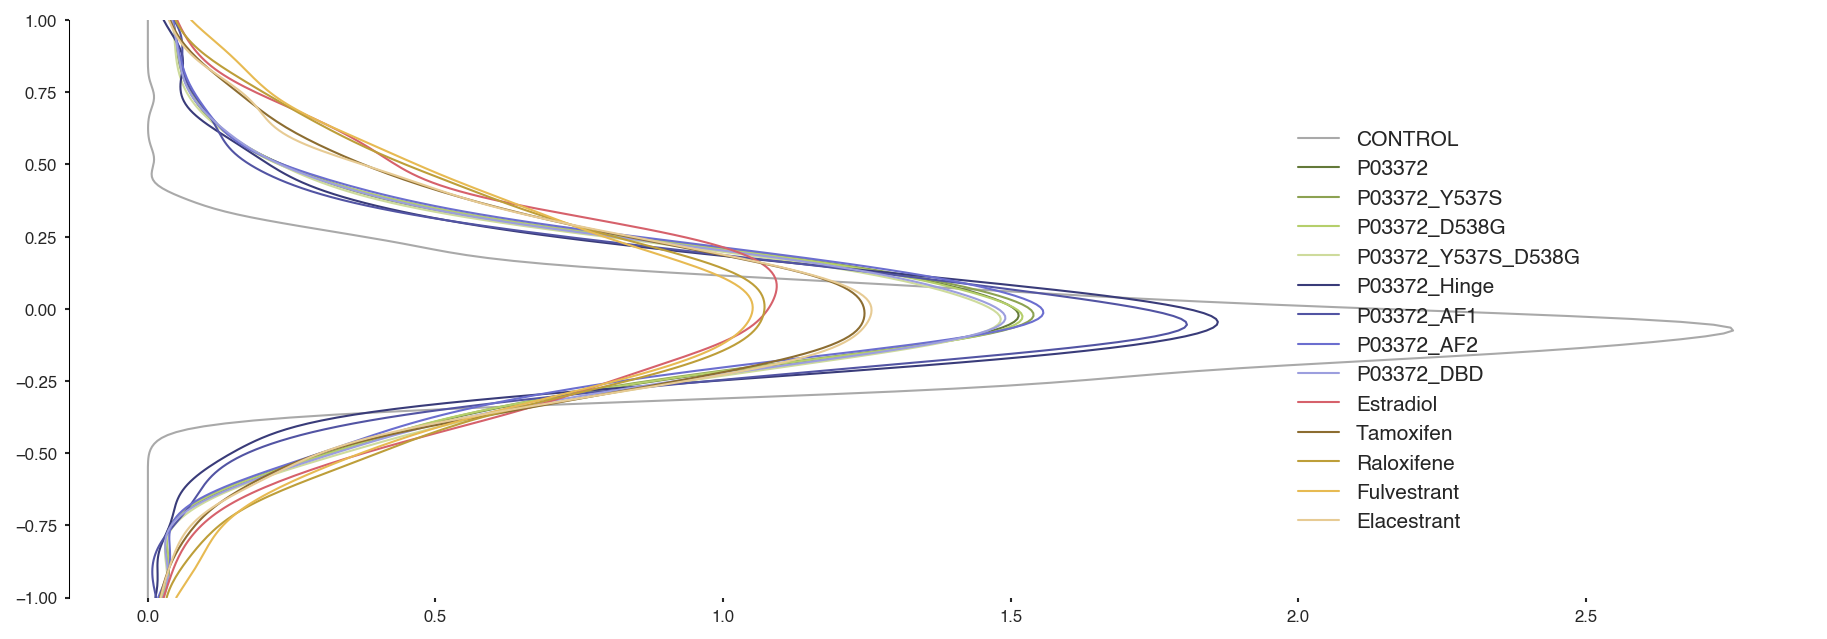

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import matplotlib as mpl

fig, ax = plt.subplots(figsize=(15, 5))

color_list = [
    "#A9A9A9", 
    "#637939", "#8ca252", "#b5cf6b", "#cedb9c",
    "#393b79", "#5254a3", "#6b6ecf", "#9c9ede",
    "#d6616b", 
    "#8c6d31", "#bd9e39", "#e7ba52", "#e7cb94"
]


row_items = list(mcf7_df.iterrows())

x_min, x_max = -1, 1
xs = np.linspace(x_min, x_max, 200)

plotted = 0
for idx, row in row_items:
    v = row.to_numpy()
    v = v[np.isfinite(v)]
    kde = st.gaussian_kde(v)
    ax.plot(kde(xs), xs, linewidth=1, label=str(idx), color=color_list[plotted % len(color_list)])
    plotted += 1

ax.set_ylim(x_min, x_max)
# ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["bottom"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(frameon=False, fontsize=10, loc=(0.7, 0.1), ncol=1)

plt.show()

## effect topDEG heatmap

In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def select_signature_genes_single_vector(df, N=25, thresh=2.0, skip_control=True):
    group2up, group2dn = {}, {}
    gene_set = set()

    for g in df.index:
        s = df.loc[g].dropna()
        # print(g, s)
        if skip_control and 'CONTROL' in g:continue

        up = s[s >= thresh].sort_values(ascending=False).index.tolist()
        dn = s[s <= -thresh].sort_values(ascending=True).index.tolist()

        if len(up) < N:
            up = s.sort_values(ascending=False).head(N).index.tolist()
        else:
            up = up[:N]

        if len(dn) < N:
            dn = s.sort_values(ascending=True).head(N).index.tolist()
        else:
            dn = dn[:N]

        group2up[g] = up
        group2dn[g] = dn
        gene_set.update(up)
        gene_set.update(dn)

    genes = [gene for gene in df.columns if gene in gene_set]  
    return genes, group2up, group2dn

def gene_wise_zscore(df):
    mu = df.mean(axis=0)
    sd = df.std(axis=0).replace(0, np.nan)
    return (df - mu) / sd


89


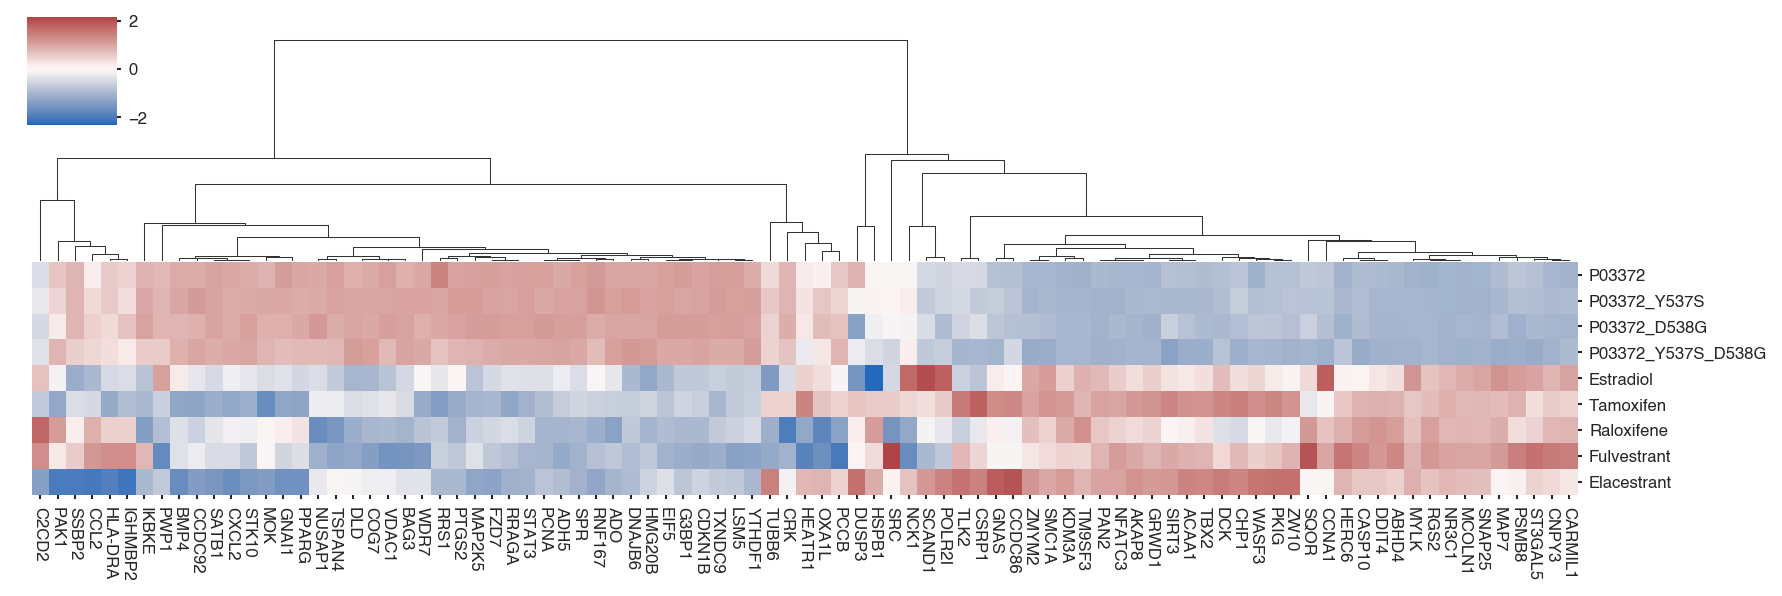

In [36]:
query = ['P03372', 'P03372_Y537S', 'P03372_D538G', 'P03372_Y537S_D538G', 
         'Estradiol', 'Tamoxifen', 'Raloxifene', 'Fulvestrant', 'Elacestrant']

df = inferenced_effect_dict['MCF7']
df.index = df.index.str.split(':').str[-1]
df = df.loc[query].copy()

genes, group2up, group2dn = select_signature_genes_single_vector(df, N=25, thresh=1.0)
print(len(genes))
df_plot = df[genes]

df_amp = df_plot.copy()
df_pat = gene_wise_zscore(df_plot)
g = sns.clustermap(
    df_pat,                 
    cmap="vlag",            
    center=0,
    metric="correlation",
    method="average",
    figsize=(12, 4),
    xticklabels=True,
    yticklabels=True,
    row_cluster=False,
    col_cluster=True,
    dendrogram_ratio=(0.01, 0.5), 
)

ax = g.ax_heatmap
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=270, ha="center", va="top")

plt.show()

## pathway enrichment

In [37]:
import pickle

with open('/data/liyiming/Project/UniPert-G2CP_reproduce/G2CP/results/ER_case_inferenced_effect.pkl', 'rb') as f:
    inferenced_effect_dict = pickle.load(f)


In [38]:
mcf7_df = inferenced_effect_dict['MCF7']
mcf7_df.index = mcf7_df.index.str.split(':').str[-1]

In [42]:
import pandas as pd

gene_sets_df = pd.read_csv(
    "../G2CP/data/h.all.v2025.1.Hs.symbols.gmt",
    header=None,
    index_col=0,
    sep="\t",
    dtype=str,       
)

hallmark_gene_sets_dict = {}
for gs_name, row in gene_sets_df.iterrows():
    genes = row.iloc[2:].dropna().astype(str).str.strip()
    genes = [g for g in genes if g]  

    seen = set()
    genes_uniq = []
    for g in genes:
        if g not in seen:
            genes_uniq.append(g)
            seen.add(g)

    if len(genes_uniq) > 0:
        hallmark_gene_sets_dict[str(gs_name)] = genes_uniq

print("n_gene_sets:", len(hallmark_gene_sets_dict))
print("example:", next(iter(hallmark_gene_sets_dict.items()))[0], "->", hallmark_gene_sets_dict[next(iter(hallmark_gene_sets_dict))][:5])

n_gene_sets: 50
example: HALLMARK_ADIPOGENESIS -> ['ABCB8', 'ACAA2', 'ACADL', 'ACADM', 'ACADS']


In [44]:
import pandas as pd
import gseapy as gp

def prerank_one_group(effect_series, gene_sets, outdir=None):
    # effect_series: index=gene, value=effect
    rnk = effect_series.sort_values(ascending=False)
    rnk_df = pd.DataFrame({"gene": rnk.index, "score": rnk.values})
    res = gp.prerank(
        rnk=rnk_df,
        gene_sets=gene_sets,
        permutation_num=1000,
        outdir=outdir, 
        seed=0,
        min_size=0,
        max_size=500
    )

    return res.res2d

nes_mat = {}
fdr_mat = {}
for g in mcf7_df.index:
    res = prerank_one_group(mcf7_df.loc[g], gene_sets=hallmark_gene_sets_dict)  
    nes_mat[g] = res["NES"]
    fdr_mat[g] = res["FDR q-val"]

nes_df = pd.DataFrame(nes_mat).T  
fdr_df = pd.DataFrame(fdr_mat).T  

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, leaves_list

def _hclust_order(M, axis=0, metric="correlation", method="average"):
    """
    M: 2D array
    axis=0 -> cluster rows; axis=1 -> cluster cols
    """
    X = M.copy()
    if np.isnan(X).any():
        if axis == 0:
            mean = np.nanmean(X, axis=1, keepdims=True)
        else:
            mean = np.nanmean(X, axis=0, keepdims=True)
        X = np.where(np.isnan(X), mean, X)

    if axis == 0:
        D = pdist(X, metric=metric)
    else:
        D = pdist(X.T, metric=metric)

    Z = linkage(D, method=method)
    return leaves_list(Z)

def plot_bubble_heatmap(
    nes_df: pd.DataFrame,
    fdr_df: pd.DataFrame,
    fdr_size="1-fdr",    
    fdr_floor=1e-300,        
    fdr_cap=50,              
    fdr_threshold=None,     
    only_significant=False,  
    cluster_rows=True,
    cluster_cols=True,
    metric="correlation",
    method="average",
    cmap="vlag",             
    vmax=None,              
    figsize=(12, 6),
    title=None,
    drop_all_nonsig_cols=True,  
    drop_all_nonsig_rows=True,  
    term_map=None,
):

    nes = nes_df.copy()
    fdr = fdr_df.copy()
    fdr = fdr.reindex(index=nes.index, columns=nes.columns)

    if drop_all_nonsig_cols and (fdr_threshold is not None):
        keep_cols = (fdr <= fdr_threshold).any(axis=0) 
        nes = nes.loc[:, keep_cols]
        fdr = fdr.loc[:, keep_cols]

    
    if drop_all_nonsig_rows:
        keep_rows = (fdr <= fdr_threshold).any(axis=1)
        nes = nes.loc[keep_rows, :]
        fdr = fdr.loc[keep_rows, :]

    M = nes.values.astype(float)
    row_order = np.arange(nes.shape[0])
    col_order = np.arange(nes.shape[1])

    if cluster_rows and nes.shape[0] > 1:
        row_order = _hclust_order(M, axis=0, metric=metric, method=method)
    if cluster_cols and nes.shape[1] > 1:
        col_order = _hclust_order(M, axis=1, metric=metric, method=method)

    nes = nes.iloc[row_order, :].iloc[:, col_order]
    fdr = fdr.iloc[row_order, :].iloc[:, col_order]

    fdr_vals = fdr.values.astype(float)
    fdr_vals = np.clip(fdr_vals, fdr_floor, 1.0)

    if fdr_size == "neglog10":
        size_val = -np.log10(fdr_vals)
        size_val = np.clip(size_val, 0, fdr_cap)
        s = 10 + 90 * (size_val / (fdr_cap if fdr_cap > 0 else 1))
        s = s ** 2 * 0.02
    elif fdr_size == "1-fdr":
        size_val = 1.0 - fdr_vals
        s = 60 * size_val
        s = s ** 2 * 0.03
    else:
        raise ValueError("fdr_size must be 'neglog10' or '1-fdr'")

    nes_vals = nes.values.astype(float)
    if vmax is None:
        q = np.nanquantile(np.abs(nes_vals), 0.99)
        vmax = float(q) if q > 0 else 1.0
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

    mask_sig = np.ones_like(fdr_vals, dtype=bool)
    if fdr_threshold is not None:
        mask_sig = fdr_vals <= fdr_threshold

    n_rows, n_cols = nes.shape
    yy, xx = np.mgrid[0:n_rows, 0:n_cols]

    fig, ax = plt.subplots(figsize=figsize)

    if only_significant and fdr_threshold is not None:
        m = mask_sig
        sc = ax.scatter(
            xx[m], yy[m],
            s=s[m],
            c=nes_vals[m],
            cmap=cmap,
            norm=norm,
            edgecolors="none"
        )
    else:
        sc = ax.scatter(
            xx[mask_sig], yy[mask_sig],
            s=s[mask_sig],
            c=nes_vals[mask_sig],
            cmap=cmap,
            norm=norm,
            edgecolors="none"
        )
        if fdr_threshold is not None:
            m = ~mask_sig
            ax.scatter(
                xx[m], yy[m],
                s=s[m]*1,
                facecolors="none",
                edgecolors="lightgray",
                linewidths=0
            )

    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels(nes.columns, rotation=90, ha="center", fontsize=8)
    ax.tick_params(axis='x', length=0)
    ax.tick_params(axis='y', length=2, width=0.5)
    ax.set_yticks(np.arange(n_rows))
    if term_map:
        ax.set_yticklabels([term_map[t] for t in nes.index], fontsize=9)
    else:
        ax.set_yticklabels(nes.index, fontsize=9)

    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.grid(False)

    if title:
        ax.set_title(title)

    plt.tight_layout()
    return fig, ax, nes, fdr

In [46]:
fdr_df.rename(columns=dict(zip(fdr_df.columns, list(res["Term"].to_list()))), inplace=True)
nes_df.rename(columns=dict(zip(nes_df.columns, list(res["Term"].to_list()))), inplace=True)

In [47]:
nes_df.head()

,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_OXIDATIVE_PHOSPHORYLATION,HALLMARK_MYC_TARGETS_V1,HALLMARK_DNA_REPAIR,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_MYC_TARGETS_V2,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_UV_RESPONSE_DN,...,HALLMARK_ANGIOGENESIS,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_PANCREAS_BETA_CELLS,HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ADIPOGENESIS,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_MTORC1_SIGNALING,HALLMARK_PEROXISOME
CONTROL,-1.492189,-1.462288,-1.354584,-1.348507,-1.311998,-1.285264,-1.254671,-1.251828,-1.234664,-1.232967,...,-0.839392,0.829539,-0.820639,-0.804308,-0.79902,0.789983,-0.737607,-0.702207,-0.697901,0.594367
P03372,-1.911707,1.824687,1.537942,1.510567,-1.426441,1.414593,-1.36269,1.34284,1.335364,-1.299983,...,-0.821178,0.799743,-0.751304,0.725762,0.714955,-0.682839,-0.671113,-0.611982,0.555225,0.368579
P03372_Y537S,-1.863076,1.778438,1.577426,1.492945,-1.416699,1.407426,1.401721,-1.364146,1.354708,-1.267753,...,0.831416,-0.796079,-0.77239,0.757224,0.743771,-0.689468,-0.685605,-0.666141,0.635096,0.507109
P03372_D538G,-1.866982,1.794769,1.541014,1.501193,-1.389028,1.37756,1.372503,-1.331943,1.318078,1.294242,...,-0.805442,-0.795924,0.773228,-0.764754,0.70876,0.671194,-0.658781,-0.621565,-0.591735,0.43846
P03372_Y537S_D538G,-1.832768,1.734142,1.51916,1.472112,1.4454,-1.409875,-1.399783,-1.386379,1.368335,-1.3225,...,0.816299,0.799502,-0.774111,0.736266,0.724947,-0.707435,-0.677153,-0.655389,-0.536508,0.447002


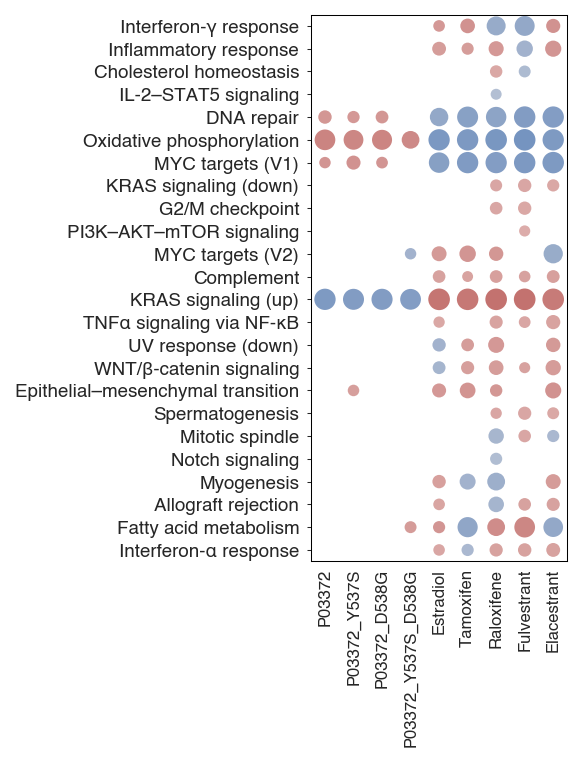

In [48]:
query = ['P03372', 'P03372_Y537S', 'P03372_D538G', 'P03372_Y537S_D538G',
         'Estradiol', 'Tamoxifen', 'Raloxifene', 'Fulvestrant', 'Elacestrant']

hallmark_name_map = {
    "HALLMARK_ADIPOGENESIS": "Adipogenesis",
    "HALLMARK_ALLOGRAFT_REJECTION": "Allograft rejection",
    "HALLMARK_ANDROGEN_RESPONSE": "Androgen response",
    "HALLMARK_ANGIOGENESIS": "Angiogenesis",
    "HALLMARK_APICAL_JUNCTION": "Apical junction",
    "HALLMARK_APICAL_SURFACE": "Apical surface",
    "HALLMARK_APOPTOSIS": "Apoptosis",
    "HALLMARK_BILE_ACID_METABOLISM": "Bile acid metabolism",
    "HALLMARK_CHOLESTEROL_HOMEOSTASIS": "Cholesterol homeostasis",
    "HALLMARK_COAGULATION": "Coagulation",
    "HALLMARK_COMPLEMENT": "Complement",
    "HALLMARK_DNA_REPAIR": "DNA repair",
    "HALLMARK_E2F_TARGETS": "E2F targets",
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": "Epithelial–mesenchymal transition",
    "HALLMARK_ESTROGEN_RESPONSE_EARLY": "Estrogen response (early)",
    "HALLMARK_ESTROGEN_RESPONSE_LATE": "Estrogen response (late)",
    "HALLMARK_FATTY_ACID_METABOLISM": "Fatty acid metabolism",
    "HALLMARK_G2M_CHECKPOINT": "G2/M checkpoint",
    "HALLMARK_GLYCOLYSIS": "Glycolysis",
    "HALLMARK_HEDGEHOG_SIGNALING": "Hedgehog signaling",
    "HALLMARK_HEME_METABOLISM": "Heme metabolism",
    "HALLMARK_HYPOXIA": "Hypoxia",
    "HALLMARK_IL2_STAT5_SIGNALING": "IL-2–STAT5 signaling",
    "HALLMARK_IL6_JAK_STAT3_SIGNALING": "IL-6–JAK–STAT3 signaling",
    "HALLMARK_INFLAMMATORY_RESPONSE": "Inflammatory response",
    "HALLMARK_INTERFERON_ALPHA_RESPONSE": "Interferon-α response",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE": "Interferon-γ response",
    "HALLMARK_KRAS_SIGNALING_DN": "KRAS signaling (down)",
    "HALLMARK_KRAS_SIGNALING_UP": "KRAS signaling (up)",
    "HALLMARK_MITOTIC_SPINDLE": "Mitotic spindle",
    "HALLMARK_MTORC1_SIGNALING": "mTORC1 signaling",
    "HALLMARK_MYC_TARGETS_V1": "MYC targets (V1)",
    "HALLMARK_MYC_TARGETS_V2": "MYC targets (V2)",
    "HALLMARK_MYOGENESIS": "Myogenesis",
    "HALLMARK_NOTCH_SIGNALING": "Notch signaling",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION": "Oxidative phosphorylation",
    "HALLMARK_P53_PATHWAY": "p53 pathway",
    "HALLMARK_PANCREAS_BETA_CELLS": "Pancreas β cells",
    "HALLMARK_PEROXISOME": "Peroxisome",
    "HALLMARK_PI3K_AKT_MTOR_SIGNALING": "PI3K–AKT–mTOR signaling",
    "HALLMARK_PROTEIN_SECRETION": "Protein secretion",
    "HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY": "Reactive oxygen species (ROS) pathway",
    "HALLMARK_SPERMATOGENESIS": "Spermatogenesis",
    "HALLMARK_TGF_BETA_SIGNALING": "TGF-β signaling",
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB": "TNFα signaling via NF-κB",
    "HALLMARK_UNFOLDED_PROTEIN_RESPONSE": "Unfolded protein response (UPR)",
    "HALLMARK_UV_RESPONSE_DN": "UV response (down)",
    "HALLMARK_UV_RESPONSE_UP": "UV response (up)",
    "HALLMARK_WNT_BETA_CATENIN_SIGNALING": "WNT/β-catenin signaling",
    "HALLMARK_XENOBIOTIC_METABOLISM": "Xenobiotic metabolism",
}

nes_df_new = nes_df.loc[query]
fdr_df_new = fdr_df.loc[query]

fig, ax, nes_ord, fdr_ord = plot_bubble_heatmap(
    nes_df_new.T,
    fdr_df_new.T,
    fdr_size="1-fdr",
    fdr_threshold=0.5,   
    only_significant=False, 
    cluster_rows=True,
    cluster_cols=False,
    figsize=(4, 5.2),
    drop_all_nonsig_rows=True,
    drop_all_nonsig_cols=True,
    vmax=3,
    term_map=hallmark_name_map
)

plt.show()